# wellfit: MCMC example (rotation, macroturbulence and thermal broadening)

This uses the same toy lines A-D as the other examples (`toy_lines.py`), but the thermal width σ_th is now fitted as
well, so there are three parameters: v sin i, v_macro and σ_th.

- True values: v sin i = 100, v_macro = 10, σ_th = 15 km/s.
- All four lines are consistent here, so the example can focus on the sampling. See the grid and optimizer examples
  for the tension diagnostic.

The thermal profile and the toy macroturbulence kernel are both Gaussians. Their convolution is a Gaussian of width
σ_tot = √(σ_th² + v_macro²), so the data constrain σ_tot but cannot separate the two. Real macroturbulence kernels
are not exactly Gaussian, but a near-degeneracy like this is common. This is where a best fit with curvature errors
breaks down and sampling the posterior pays off.

wellfit's part is the likelihood, `wf.log_likelihood(residuals, err, n_corr, sigma_sys)` = −chi2_eff/2 + const. It uses
the rescaled errors, counts independent pixels, and includes the systematic floor. We compare it with the naive
likelihood: quoted errors, every pixel independent, no floor.

In [1]:
import sys
sys.path.insert(0, '..')   # or install the package: pip install -e ..
import numpy as np
import matplotlib.pyplot as plt
import emcee, corner
import wellfit as wf
import toy_lines as tl
from scipy.optimize import minimize
%matplotlib inline

## 1. Data and noise

error scale factor = 1.26 (injected 1.25); n_corr = 4.94 (injected 5.32)


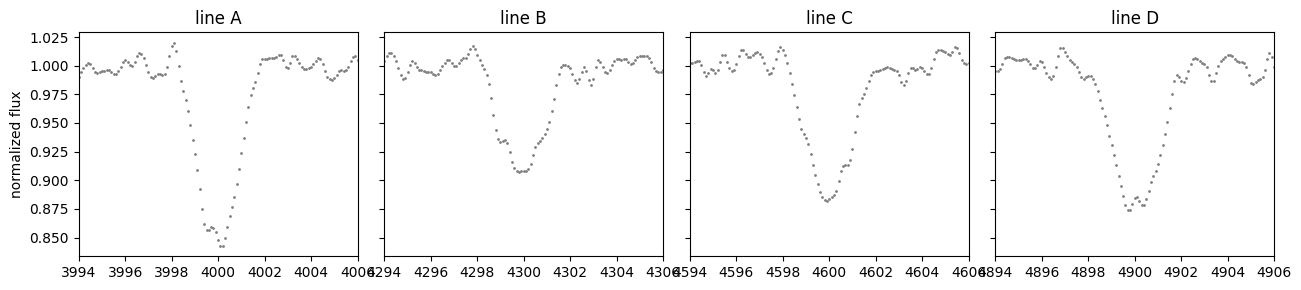

In [2]:
TRUTH = dict(vsini=100., vmacro=10., sigma_th=15.)
d = tl.make_data(vsini=TRUTH['vsini'], vmacro=TRUTH['vmacro'], sigma_th=TRUTH['sigma_th'], vsini_D=TRUTH['vsini'], snr=150.)
lam, flux, err_quoted, groups, names = d['lam'], d['flux'], d['err'], d['groups'], d['names']

err, factor = wf.measure_error_scale(lam, flux, err_quoted, d['ref_ranges'], deg=0)
n_corr, rho = wf.measure_n_corr(lam, flux, err, d['ref_ranges'], deg=0)
print(f"error scale factor = {factor:.2f} (injected 1.25); n_corr = {n_corr:.2f} (injected {d['truth']['n_corr']:.2f})")

fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.plot(lam[m], flux[m], '.', ms=2, color='0.5'); ax.set_title(f'line {names[j]}')
    ax.set_xlim(tl.LINES[names[j]][0] - 6, tl.LINES[names[j]][0] + 6)
axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 2. Best fit and systematic floor (optimizer stream)

MCMC needs `sigma_sys` and a starting point. `fit_optimizer` provides both: it alternates the fit and `sigma_sys`
until the best fit has reduced chi2_eff = 1.

Its curvature errors show the degeneracy. Along the σ_th–v_macro direction chi2_eff is almost flat, so the
curvature is close to zero and the "errors" on v_macro and σ_th are meaningless.

In [3]:
PARAMS = ['vsini', 'vmacro', 'sigma_th']

def residuals(theta):
    return tl.model(lam, groups, *theta) - flux

def nelder_mead(objective, theta_start):
    return minimize(objective, theta_start, method='Nelder-Mead', bounds=[(0, 400)] * len(theta_start),
                    options={'xatol': 1e-3, 'fatol': 1e-6, 'maxiter': 5000}).x

fit = wf.fit_optimizer(residuals, nelder_mead, [80., 20., 20.], err, n_corr, param_names=PARAMS)
print(fit.summary())

n_data = 1204, n_corr = 4.94 -> 243.8 independent points, nu = 240.8
sigma_sys = 0.001937; best fit: chi2 = 1288.0 (raw), chi2_eff = 240.8
Parameters (value +stat -stat, +sys -sys):
  vsini           99.04  +2.772 -2.772   sys +0 -0
  vmacro          21.95  +423 -423   sys +0 -0
  sigma_th        1.515  +6129 -6129   sys +0 -0


## 3. Sampling: naive vs wellfit likelihood

Priors are flat over 0-300 km/s for v sin i and 0-100 km/s for v_macro and σ_th. The two runs differ only in the
likelihood. `sigma_sys` is fixed at the optimizer's value. To sample it as a free parameter instead, pass it per step:
`log_likelihood` includes the normalization term that sampling it requires.

In [4]:
LO, HI = np.zeros(3), np.array([300., 100., 100.])

def log_prior(theta):
    return 0. if np.all((theta >= LO) & (theta <= HI)) else -np.inf

def log_post_wellfit(theta, prior=log_prior):
    lp = prior(theta)
    return lp + wf.log_likelihood(residuals(theta), err, n_corr, fit.sigma_sys) if np.isfinite(lp) else -np.inf

def log_post_naive(theta):
    lp = log_prior(theta)
    return lp + wf.log_likelihood(residuals(theta), err_quoted, 1., 0.) if np.isfinite(lp) else -np.inf

N_WALKERS, N_STEPS, BURN = 32, 4000, 1000

def run(log_post, seed=0):
    rng = np.random.default_rng(seed)
    p0 = np.abs(fit.theta + 0.5 * rng.normal(size=(N_WALKERS, 3)))
    sampler = emcee.EnsembleSampler(N_WALKERS, 3, log_post)
    sampler.run_mcmc(p0, N_STEPS)
    tau = sampler.get_autocorr_time(tol=0)
    print(f"acceptance {sampler.acceptance_fraction.mean():.2f}; autocorrelation times {np.round(tau)} steps "
          f"(chain = {N_STEPS / tau.max():.0f} x the longest)")
    return sampler.get_chain(discard=BURN, thin=10, flat=True)

chain_naive = run(log_post_naive)
chain_wf = run(log_post_wellfit)

acceptance 0.47; autocorrelation times [ 57. 155. 159.] steps (chain = 25 x the longest)


acceptance 0.56; autocorrelation times [50. 71. 64.] steps (chain = 56 x the longest)


In [5]:
def summarize(chain, label):
    q = np.percentile(chain, [16, 50, 84], axis=0)
    tot = np.percentile(np.hypot(chain[:, 1], chain[:, 2]), [16, 50, 84])
    cols = [f"{k} = {q[1, i]:5.1f} +{q[2, i] - q[1, i]:4.1f} -{q[1, i] - q[0, i]:4.1f}" for i, k in enumerate(PARAMS)]
    cols.append(f"sigma_tot = {tot[1]:4.1f} +{tot[2] - tot[1]:3.1f} -{tot[1] - tot[0]:3.1f}")
    print(f"{label:22s}" + "   ".join(cols))

summarize(chain_naive, 'naive')
summarize(chain_wf, 'wellfit')
print(f"{'truth':22s}" + "   ".join(f"{k} = {TRUTH[k]:5.1f}" for k in PARAMS)
      + f"   sigma_tot = {np.hypot(TRUTH['vmacro'], TRUTH['sigma_th']):4.1f}")

naive                 vsini =  99.0 + 0.9 - 1.0   vmacro =  16.0 + 5.2 -10.4   sigma_th =  15.1 + 6.0 - 9.5   sigma_tot = 22.1 +1.2 -1.3
wellfit               vsini =  98.4 + 2.8 - 3.2   vmacro =  15.4 + 7.0 -10.1   sigma_th =  15.2 + 7.3 - 9.9   sigma_tot = 22.8 +4.1 -3.8
truth                 vsini = 100.0   vmacro =  10.0   sigma_th =  15.0   sigma_tot = 18.0


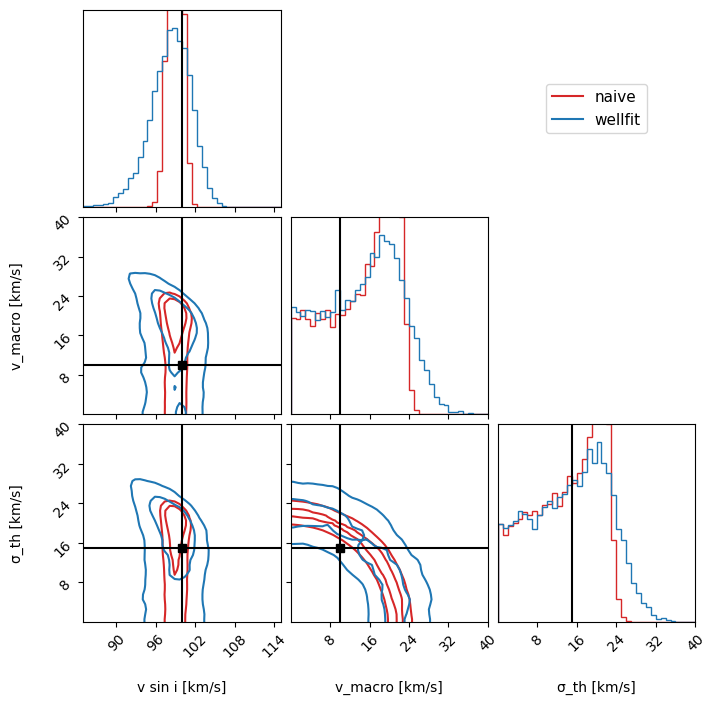

In [6]:
RANGE = [(85, 115), (0, 40), (0, 40)]
LABELS = ['v sin i [km/s]', 'v_macro [km/s]', 'σ_th [km/s]']
TRUTHS = [TRUTH[k] for k in PARAMS]
kw = dict(range=RANGE, labels=LABELS, bins=40, smooth=1.0, levels=[0.393, 0.865], plot_datapoints=False,
          plot_density=False, fill_contours=False)   # levels: 1 and 2 sigma in 2D
fig = corner.corner(chain_naive, color='C3', **kw)
corner.corner(chain_wf, fig=fig, color='C0', truths=TRUTHS, truth_color='k', **kw)
fig.axes[2].plot([], [], 'C3', label='naive'); fig.axes[2].plot([], [], 'C0', label='wellfit')
fig.axes[2].legend(loc='center', fontsize=11)
fig.set_size_inches(7.5, 7.5)

The v_macro–σ_th panel shows the degeneracy as an arc along σ_th² + v_macro² ≈ const. A best fit with curvature
errors cannot represent that shape. Both posteriors pile up toward v_macro = 0 and σ_th = 0, the two ends of the arc
where the other parameter takes all the width.

The naive arc is much thinner. The table above puts numbers on it: naive σ_tot = 22.1 ± 1.2 km/s is about 3σ from
the true 18.0, while wellfit's 22.8 ± 4 is within about 1σ. The naive v sin i error, ±1 km/s, is likewise about
3× too small.

## 4. What the data do constrain: the combined width

σ_tot = √(σ_th² + v_macro²) is constrained, even though σ_th and v_macro are not separately.

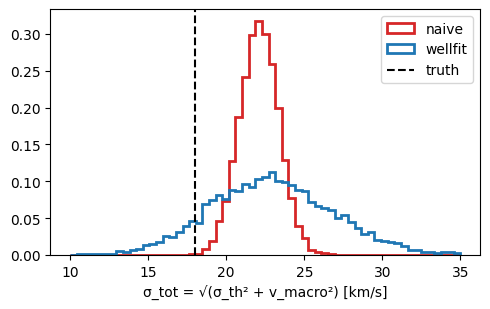

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.2))
bins = np.linspace(10, 35, 60)
for ch, col, lab in [(chain_naive, 'C3', 'naive'), (chain_wf, 'C0', 'wellfit')]:
    ax.hist(np.hypot(ch[:, 1], ch[:, 2]), bins, density=True, histtype='step', color=col, lw=2, label=lab)
ax.axvline(np.hypot(TRUTH['vmacro'], TRUTH['sigma_th']), color='k', ls='--', label='truth')
ax.set_xlabel('σ_tot = √(σ_th² + v_macro²) [km/s]'); ax.legend(); plt.tight_layout()

## 5. Breaking the degeneracy with a prior

If σ_th is known independently, for example from a temperature measured elsewhere, put it in as a prior. Here we
use a Gaussian prior σ_th = 14 ± 2 km/s, deliberately not centred on the truth. Through the σ_tot constraint, the
prior on σ_th narrows v_macro and removes the pile-up at v_macro = 0. How well v_macro is then measured depends on
how well σ_tot is constrained.

acceptance 0.64; autocorrelation times [38. 40. 36.] steps (chain = 100 x the longest)
wellfit, flat priors  vsini =  98.4 + 2.8 - 3.2   vmacro =  15.4 + 7.0 -10.1   sigma_th =  15.2 + 7.3 - 9.9   sigma_tot = 22.8 +4.1 -3.8
wellfit, σ_th prior   vsini =  99.1 + 2.6 - 3.1   vmacro =  16.6 + 5.0 - 6.4   sigma_th =  14.2 + 2.0 - 2.0   sigma_tot = 21.8 +3.9 -3.8


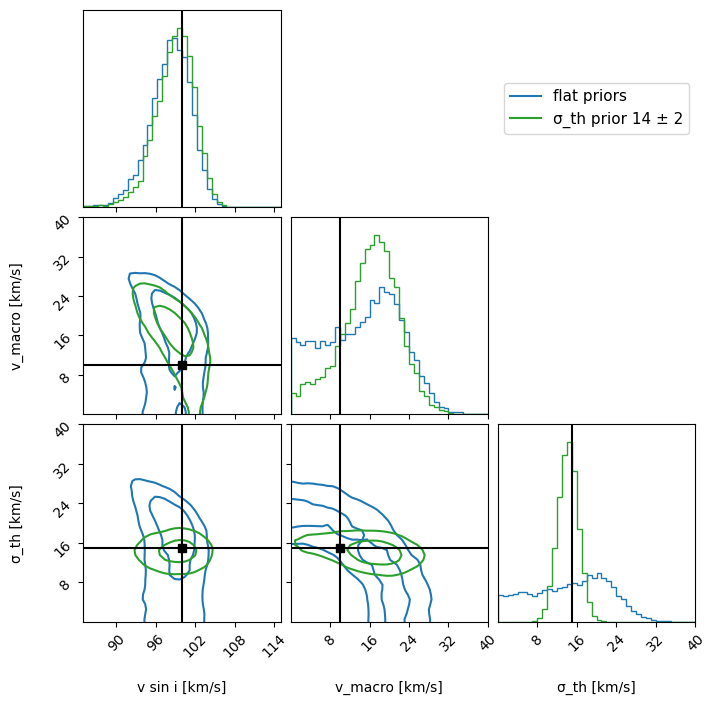

In [8]:
def log_prior_thermal(theta, mu=14., sd=2.):
    lp = log_prior(theta)
    return lp - 0.5 * ((theta[2] - mu) / sd)**2 if np.isfinite(lp) else -np.inf

chain_prior = run(lambda th: log_post_wellfit(th, prior=log_prior_thermal))
summarize(chain_wf, 'wellfit, flat priors')
summarize(chain_prior, 'wellfit, σ_th prior')

fig = corner.corner(chain_wf, color='C0', **kw)
corner.corner(chain_prior, fig=fig, color='C2', truths=TRUTHS, truth_color='k', **kw)
fig.axes[2].plot([], [], 'C0', label='flat priors'); fig.axes[2].plot([], [], 'C2', label='σ_th prior 14 ± 2')
fig.axes[2].legend(loc='center', fontsize=11)
fig.set_size_inches(7.5, 7.5)

## Summary

- Use `wf.log_likelihood` with rescaled errors, n_corr and `sigma_sys` from `fit_optimizer` (or `fit_grid`). The
  posterior widths then reflect the independent information in the data. The naive likelihood is about √n_corr too
  narrow and can exclude the truth.
- With degenerate parameters, quote what the data constrain (σ_tot here), or add independent information as a prior.
  Curvature errors cannot describe such a posterior.
- Check convergence: the chains should be many autocorrelation times long (printed for each run above).